# 01: Data and exploratory analysis

**Offline reproduction.** This notebook reads committed statistical observations and regenerates the first two existing EDA figures. No API key, download, model call or private report corpus is required. Run all cells from the checkout, with the environment installed by `make setup`; `make notebooks` supplies optional Jupyter packages.

The supported answer window is 2024-Q1 to 2026-Q2. Earlier observations are historical context, not additional answer scope. Sources, rights and transformations: [data sheet](../docs/data-sheet.md). Generated findings: [EDA record](../artifacts/data-quality/eda-findings.md). Source attribution: MOM and SingStat through [data.gov.sg](https://data.gov.sg/), subject to the [Singapore Open Data Licence](https://developers.data.gov.sg/open-data-licence) where applicable. No agency endorsement is implied.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'data/processed/observations.parquet').is_file())
def load_json(relative):
    return json.loads((ROOT / relative).read_text())


In [2]:
obs = pd.read_parquet(ROOT / 'data/processed/observations.parquet')
coverage = obs.groupby('source_id', sort=True).agg(
    rows=('observation_id', 'size'), in_scope=('in_answer_scope', 'sum'),
    first_period=('period', 'min'), last_period=('period', 'max'),
    missing=('value', lambda values: int(values.isna().sum())),
)
assert len(coverage) == 36
assert len(obs) == 52020
assert int(obs.in_answer_scope.sum()) == 4300
assert obs.observation_id.is_unique
scoped = obs.loc[obs.in_answer_scope]
assert scoped.period.min() == '2024-Q1' and scoped.period.max() == '2026-Q2'
display(pd.DataFrame([{'tables': len(coverage), 'rows': len(obs), 'in_scope': len(scoped)}]))
with pd.option_context('display.max_rows', 36):
    display(coverage)


,tables,rows,in_scope
0,36,52020,4300


,rows,in_scope,first_period,last_period,missing
source_id,,,,,
avg_weekly_paid_hours_quarterly,114,10,1998-Q1,2026-Q2,0
citizen_unemployment_rate,276,20,1992-Q1,2026-Q2,0
employment_change_by_sector,3692,260,1991-Q1,2026-Q2,2680
job_vacancies_by_industry,4700,420,1998-Q1,2026-Q2,23
job_vacancies_by_occupation,450,50,1998-Q1,2026-Q2,0
job_vacancy_count,114,10,1998-Q1,2026-Q2,0
job_vacancy_rate,114,10,1998-Q1,2026-Q2,0
job_vacancy_rate_by_industry,4700,420,1998-Q1,2026-Q2,23
job_vacancy_rate_by_occupation,450,50,1998-Q1,2026-Q2,0


## Definitions before comparison

Each row keeps its source, snapshot, source locator, population, seasonal adjustment, unit, dimension, release stage and missing-value reason. Do not add different populations or top-level and nested industries. Rates are percentages; differences in rates are percentage points. The vacancy ratio is vacancies per unemployed person, not a percentage. Its population basis is not the resident-only unemployment series, so the two lines do not establish a common denominator or a causal relationship.

Undefined dashes remain missing, not measured zero. The existing industry chart substitutes zero only for stacking and notes rounding to ten persons. Dataset employment-change totals and report headlines have an unresolved definition difference; do not silently join them. Three datasets have assumed, not verified, open licensing; their derived rows are in the committed parquet, although their raw CSVs remain local. This notebook does not resolve those rights.


In [3]:
definitions = scoped[['source_id', 'population', 'adjustment', 'unit', 'release_stage']].drop_duplicates()
display(definitions.head(12))
display(obs.groupby('missing_reason', dropna=False).size().rename('rows').to_frame())


,source_id,population,adjustment,unit,release_stage
104,avg_weekly_paid_hours_quarterly,employees,unspecified,hours_per_week,dataset_snapshot
246,employment_change_by_sector,unverified_basis,not_applicable,persons,dataset_snapshot
3910,job_vacancy_count,establishments,unspecified,vacancies,dataset_snapshot
3992,job_vacancies_by_industry,establishments,unspecified,vacancies,dataset_snapshot
8724,job_vacancies_by_occupation,establishments,unspecified,vacancies,dataset_snapshot
9174,job_vacancy_rate,establishments,unspecified,percent,dataset_snapshot
9256,job_vacancy_rate_by_industry,establishments,unspecified,percent,dataset_snapshot
13988,job_vacancy_rate_by_occupation,establishments,unspecified,percent,dataset_snapshot
14438,vacancy_to_unemployed_ratio,not_applicable,seasonally_adjusted,ratio,dataset_snapshot
14552,recruitment_rate,establishments,unspecified,percent,dataset_snapshot


,rows
missing_reason,
dash_marker_publisher_does_not_define_nil_vs_suppressed,4777
source_token:'-',80
source_token:'na',4664
NaN,42499


## Finding 1: vacancy pressure eased from its 2022 peak

The existing dual-axis figure uses 2019 onwards for context and shades the supported answer window. Read the axes separately. The expected ratio peak is 2.55 in 2022-Q2, falling to 1.48 in 2026-Q2. Resident seasonally adjusted unemployment ranges from 2.6% to 2.9% within scope, ending at 2.9%. These are descriptive comparisons, not a causal explanation.


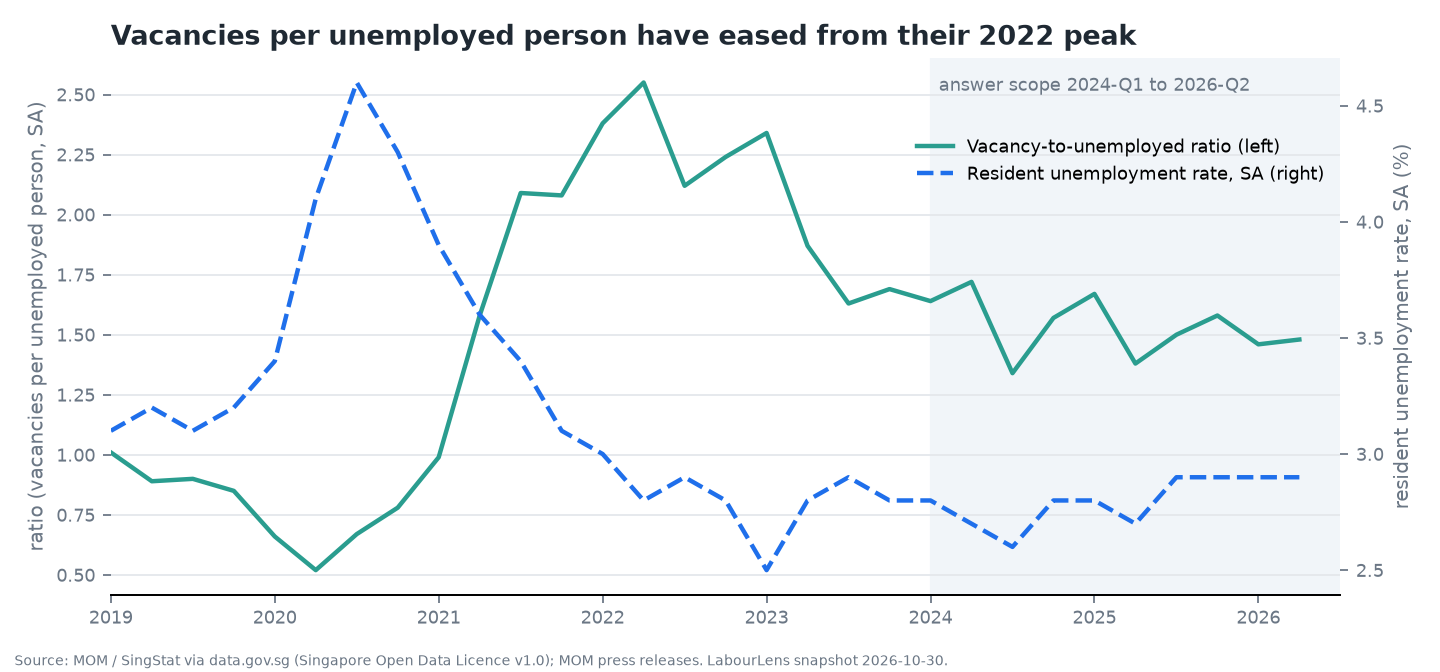

,recomputed finding
ratio_peak_period,2022-Q2
ratio_peak,2.55
ratio_last_period,2026-Q2
ratio_last,1.48
ur_last,2.9
ur_scope_min,2.6
ur_scope_max,2.9


In [4]:
from tempfile import TemporaryDirectory
from IPython.display import Image
from labourlens.data.eda import fig_vacancy_vs_unemployment, fig_retrenchment

# Reuse the figure implementation without overwriting committed PNGs or findings.
with TemporaryDirectory(prefix='labourlens-notebook-') as directory:
    figure_path = Path(directory) / 'vacancy.png'
    vacancy = fig_vacancy_vs_unemployment(obs, figure_path)
    display(Image(filename=str(figure_path), width=850))
assert vacancy == {
    'ratio_peak_period': '2022-Q2', 'ratio_peak': 2.55,
    'ratio_last_period': '2026-Q2', 'ratio_last': 1.48,
    'ur_last': 2.9, 'ur_scope_min': 2.6, 'ur_scope_max': 2.9,
}
display(pd.Series(vacancy, name='recomputed finding').to_frame())


## Finding 2: retrenchments increased in 2026-Q2

The quarterly total rises from 3,830 to 4,620, an increase of 20.6% after rounding. Services account for approximately 77% of the latest total. The chart's right panel contains only top-level industries; it does not add their subcategories again. Values are publisher-rounded, so summed industry counts need not exactly match the total.


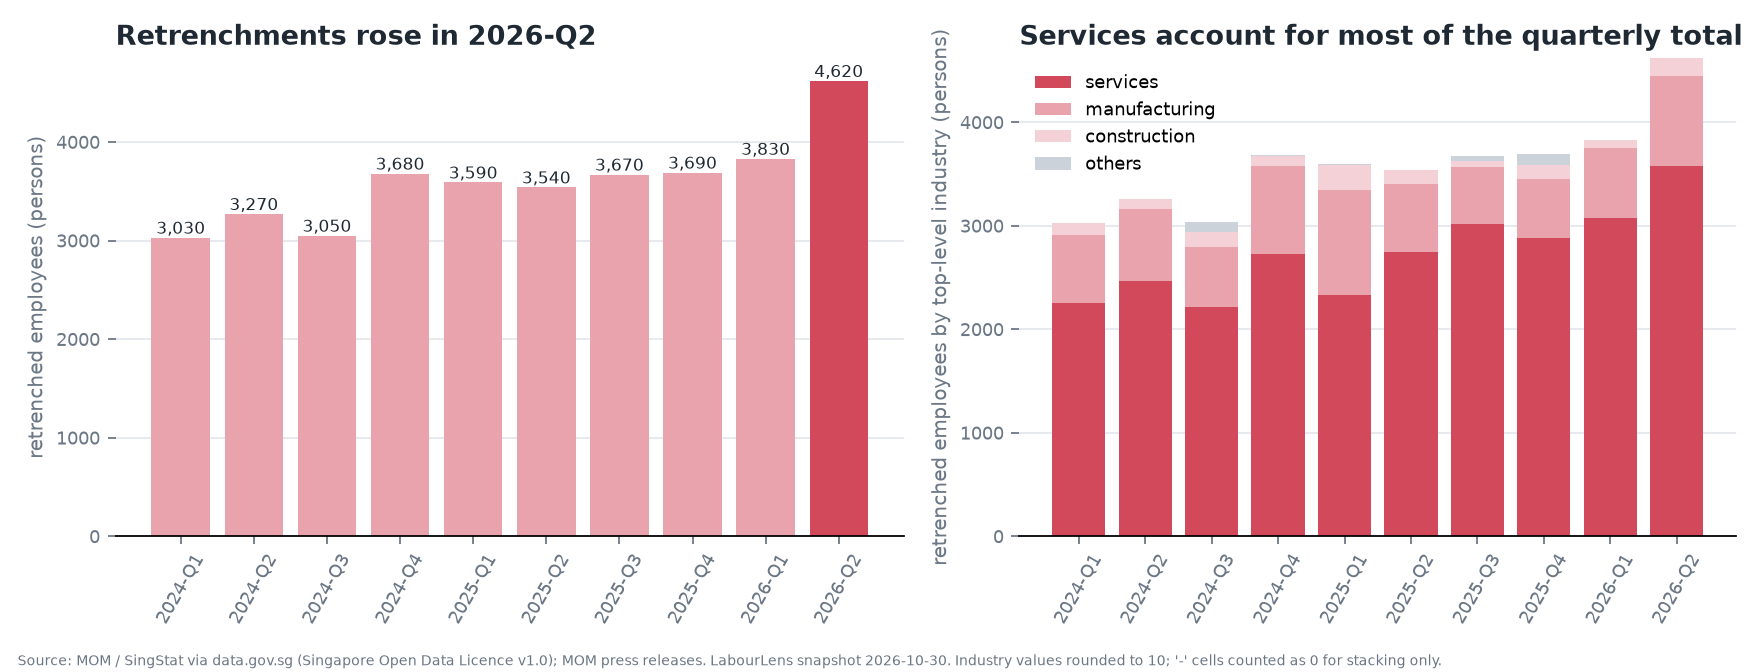

,recomputed finding
last_period,2026-Q2
last,4620.0
prev_period,2026-Q1
prev,3830.0
pct_change,20.626632
services_share_last,77.489177


In [5]:
with TemporaryDirectory(prefix='labourlens-notebook-') as directory:
    figure_path = Path(directory) / 'retrenchments.png'
    retrenchment = fig_retrenchment(obs, figure_path)
    display(Image(filename=str(figure_path), width=1000))
assert retrenchment['prev_period'] == '2026-Q1' and retrenchment['prev'] == 3830
assert retrenchment['last_period'] == '2026-Q2' and retrenchment['last'] == 4620
assert round(retrenchment['pct_change'], 1) == 20.6
assert round(retrenchment['services_share_last']) == 77
display(pd.Series(retrenchment, name='recomputed finding').to_frame())


## What this reproduction does not establish

It checks the committed store and chart calculations, not the original extraction or publisher files. Source re-acquisition, passage inspection and rights scanning require the local restricted corpus and the documented ingestion process. Findings remain subject to the data sheet's definition, revision, missingness and review limitations. No forecasting or policy-effect estimate is made here.
